# Iowa Liquor Sales Analysis

**Question:** What drives liquor pricing and sales patterns across Iowa, and can product attributes predict price and category?

**Data:** Iowa Liquor Sales, published by the State of Iowa, which records wholesale spirits orders placed by licensed retailers. I analyzed a random 1% sample (`random_state=54`) covering 2012–2025.

**Tools:** Python (pandas, scikit-learn, statsmodels, matplotlib, seaborn), SQL (SQLite)

**Highlights:**
- Cleaned and validated the data, including fixing county numbers corrupted by mode imputation
- Built an OLS regression explaining ~40% of variation in bottle price (RMSE ≈ \$11)
- Trained a Decision Tree that classifies product category with 84% test accuracy
- Segmented products into 5 K-Means clusters with distinct price tiers and product types

## Data Cleaning & Preparation

The full Iowa Liquor Sales dataset contains millions of records, so I worked with a random 1% sample (`random_state=54`) to keep processing manageable while preserving the overall distribution. The sample contained no duplicate rows.

**Data types:** Identifier columns such as zip code, item number, category, vendor number, and county number were stored as floats (e.g., `50010.0`). Since these are labels rather than quantities, I converted them to strings and removed the trailing `.0`.

**Missing values:** Missing categorical values were imputed with each column's mode.

**Outliers:** Using the IQR method, several numeric columns showed a large number of outliers. On inspection, these reflected real variation (bulk orders, unusual bottle sizes) rather than entry errors, so I kept them rather than imposing artificial cutoffs.

**Feature engineering:** I converted the date column to datetime and added year, month, day of week, a federal-holiday flag (using pandas' `USFederalHolidayCalendar`), and season based on standard equinox/solstice dates. Column names were standardized to lowercase snake_case.

In [1]:
#Sampled 1% of the data using frac=0.01
#Displays first and last 5 rows, the shape of the data (rows and columns)
#Checks for duplicate rows
import pandas as pd
iowa = pd.read_csv("Iowa_Liquor_Sales_20250902 (1).csv")
iowa_sample = iowa.sample(frac=0.01, random_state = 54)
print(iowa_sample.head())
print(iowa_sample.tail())
print(iowa_sample.shape)
print(iowa_sample.duplicated().sum())

         Invoice/Item Number        Date  Store Number  \
3368745         S18048700038  03/24/2014          2535   
2181289         S18776300103  05/05/2014          2515   
31371691        S21386500023  09/23/2014          4334   
14234573     INV-33464800053  01/14/2021          4969   
11407373     INV-53850300067  12/09/2022          4291   

                                 Store Name                 Address  \
3368745          HY-VEE FOOD STORE #1 / WDM     1700 VALLEY WEST DR   
2181289   HY-VEE FOOD STORE #1 / MASON CITY          2400 4TH ST SW   
31371691      FAREWAY STORES #114 / DUBUQUE  2050 JOHN F KENNEDY RD   
14234573      LAKE LIQUORS WINE AND SPIRITS          910 N 8TH ST W   
11407373      FAREWAY STORES #597 / CRESTON          105 E ADAMS ST   

                     City Zip Code                Store Location  \
3368745   WEST DES MOINES    50265                           NaN   
2181289        MASON CITY    50401  POINT (-93.235588 43.148451)   
31371691          DU

In [2]:
#This cell changes data types
#Any categorical columns that have missing values are replaced with the mode
#Outliers are checked using the IQR method
iowa_sample.dtypes
iowa_sample['Zip Code'] = iowa_sample['Zip Code'].astype(str).str.replace('.0', '', regex=False)
iowa_sample['Item Number'] = iowa_sample['Item Number'].astype(str).str.replace('.0', '', regex=False)
iowa_sample['Category'] = iowa_sample['Category'].astype(str).str.replace('.0', '', regex=False)
iowa_sample['Vendor Number'] = iowa_sample['Vendor Number'].astype(str).str.replace('.0', '', regex=False)
iowa_sample['County Number'] = iowa_sample['County Number'].astype(str).str.replace('.0', '', regex=False)

iowa_sample.dtypes

categorical = iowa_sample.select_dtypes(include='object').columns
for x in categorical:
    iowa_sample[x] = iowa_sample[x].fillna(iowa_sample[x].mode()[0])

iowa_sample.isna().sum()

numeric = ['Pack', 'Bottle Volume (ml)', 'State Bottle Cost', 'State Bottle Retail',
                 'Bottles Sold', 'Sale (Dollars)', 'Volume Sold (Liters)', 'Volume Sold (Gallons)']

Q1 = iowa_sample[numeric].quantile(0.25)
Q3 = iowa_sample[numeric].quantile(0.75)
IQR = Q3 - Q1
outliers = ((iowa_sample[numeric] < (Q1 - 1.5 * IQR)) | (iowa_sample[numeric] > (Q3 + 1.5 * IQR))).sum()
outliers
#No further action was done to change outliers, based on the IQR. 
#I do not want to implement anything that will create odd cutoffs when the data is real and not misentered.

Pack                     38035
Bottle Volume (ml)       97336
State Bottle Cost        20228
State Bottle Retail      20231
Bottles Sold             15664
Sale (Dollars)           19437
Volume Sold (Liters)     11567
Volume Sold (Gallons)    14565
dtype: int64

In [3]:
#Converts date columns to datetime format
#Columns added for year, month, and day of the week
#Columns also adding whether it was a public holiday or the particular season
iowa_sample['Date'] = pd.to_datetime(iowa_sample['Date'])

iowa_sample['year'] = iowa_sample['Date'].dt.year
iowa_sample['month'] = iowa_sample['Date'].dt.month
iowa_sample['day_of_week'] = iowa_sample['Date'].dt.day_name()

from pandas.tseries.holiday import USFederalHolidayCalendar
holidays = USFederalHolidayCalendar().holidays(start=iowa_sample['Date'].min(), end=iowa_sample['Date'].max())
iowa_sample['is_holiday'] = iowa_sample['Date'].isin(holidays)

def get_season(date):
    year = date.year
    spring_start = pd.Timestamp(year, 3, 20)
    summer_start = pd.Timestamp(year, 6, 21)
    fall_start = pd.Timestamp(year, 9, 22)
    winter_start = pd.Timestamp(year, 12, 21)

    if date >= spring_start and date < summer_start:
        return 'Spring'
    elif date >= summer_start and date < fall_start:
        return 'Summer'
    elif date >= fall_start and date < winter_start:
        return 'Fall'
    else:
        return 'Winter'

iowa_sample['season'] = iowa_sample['Date'].apply(get_season)

iowa_sample.columns = (
    iowa_sample.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('(', '', regex=False)
    .str.replace(')', '', regex=False)
    .str.replace('/', '_', regex=False)
)

iowa_sample.head()
#This is the first 5 rows of the 1% sampled data after all of the previous cleaning done in this problem.

,invoice_item_number,date,store_number,store_name,address,city,zip_code,store_location,county_number,county,...,state_bottle_retail,bottles_sold,sale_dollars,volume_sold_liters,volume_sold_gallons,year,month,day_of_week,is_holiday,season
3368745,S18048700038,2014-03-24,2535,HY-VEE FOOD STORE #1 / WDM,1700 VALLEY WEST DR,WEST DES MOINES,50265,POINT (-93.596754 41.554101),77,POLK,...,11.76,6,70.56,10.5,2.77,2014,3,Monday,False,Spring
2181289,S18776300103,2014-05-05,2515,HY-VEE FOOD STORE #1 / MASON CITY,2400 4TH ST SW,MASON CITY,50401,POINT (-93.235588 43.148451),17,CERRO GORDO,...,10.91,2,21.82,1.5,0.40,2014,5,Monday,False,Spring
31371691,S21386500023,2014-09-23,4334,FAREWAY STORES #114 / DUBUQUE,2050 JOHN F KENNEDY RD,DUBUQUE,52001,POINT (-93.596754 41.554101),31,DUBUQUE,...,14.00,2,28.00,1.5,0.40,2014,9,Tuesday,False,Fall
14234573,INV-33464800053,2021-01-14,4969,LAKE LIQUORS WINE AND SPIRITS,910 N 8TH ST W,CLEAR LAKE,50428,POINT (-93.396651 43.142775),17,CERRO GORDO,...,18.89,12,226.68,12.0,3.17,2021,1,Thursday,False,Winter
11407373,INV-53850300067,2022-12-09,4291,FAREWAY STORES #597 / CRESTON,105 E ADAMS ST,CRESTON,50801,POINT (-94.36134 41.05731),77,UNION,...,22.50,18,405.00,31.5,8.32,2022,12,Friday,False,Fall


## Data Validation & Exploratory Analysis

**County validation (SQL):** Loading the data into SQLite confirmed all 99 Iowa counties were present, but revealed that mode imputation had assigned the most common county number to records that were missing one, creating mismatches between county names and numbers. Since Iowa county numbers follow alphabetical order, I rebuilt the mapping from county name and re-validated it with SQL, which returned no conflicts.

**Profit margin:** I calculated margin as (retail − cost) / retail × 100, setting rows with \$0 retail to null so they wouldn't distort the average. The mean margin was about 33%.

**Timing patterns:**
- December was consistently a top month, likely driven by holiday demand.
- Monday through Wednesday had the most records, while Sunday had none until 2019 and rose noticeably by 2024. This suggests the data reflects store orders from distributors rather than individual retail purchases, and that recording practices changed over time.
- 2025 is a partial year, so it's excluded from year-level conclusions.

**Top products:** I grouped products into vodkas, whiskeys, and liqueurs/cordials by keyword matching on category names. Hawkeye Vodka was a consistent leader, and Tito's entered the top three from 2017 onward. Fireball, Black Velvet, Jägermeister, and Baileys were also consistent top sellers. Fireball appeared under multiple names and categories, an example of inconsistent product naming in the source data.

**Scope note:** This dataset covers wholesale spirits sales only (no beer or wine, no individual consumption), so it can describe statewide sales trends but can't measure drinking behavior.

In [4]:
#This cell imports SQL and checks for the 99 counties
#Rebuilds county numbers from county names and re-validates
#Profit margin is calculated

import sqlite3
conn = sqlite3.connect(':memory:')

iowa_sample.to_sql('iowa', conn, index=False, if_exists='replace')
query = "SELECT DISTINCT county FROM iowa"
result = pd.read_sql(query, conn)
print(result.shape)
print(sorted(result['county'].tolist()))

query = """
SELECT county_number, COUNT(DISTINCT county) as distinct_names
FROM iowa
GROUP BY county_number
HAVING COUNT(DISTINCT county) > 1
"""
print(pd.read_sql(query, conn))

county_list = sorted(result['county'].tolist())
county_number_map = {county: i + 1 for i, county in enumerate(county_list)}
iowa_sample['county_number'] = iowa_sample['county'].map(county_number_map)

iowa_sample.to_sql('iowa', conn, index=False, if_exists='replace')

query = """
SELECT county_number, COUNT(DISTINCT county) as distinct_names
FROM iowa
GROUP BY county_number
HAVING COUNT(DISTINCT county) > 1
"""
print(pd.read_sql(query, conn))

iowa_sample['profit_margin_pct'] = (
    (iowa_sample['state_bottle_retail'] - iowa_sample['state_bottle_cost'])
    / iowa_sample['state_bottle_retail'] * 100
)
print(iowa_sample['profit_margin_pct'].mean())
print((iowa_sample['state_bottle_retail'] == 0).sum())

print(iowa_sample[iowa_sample['state_bottle_retail'] == 0][['state_bottle_cost', 'state_bottle_retail', 'profit_margin_pct']])
iowa_sample.loc[iowa_sample['state_bottle_retail'] == 0, 'profit_margin_pct'] = pd.NA
iowa_sample['profit_margin_pct'].mean()

#For calculating the profit margin, it is retail minus the cost then divided by the retail multiplied by 100 to get the number in a clean percentage.



(99, 1)
['ADAIR', 'ADAMS', 'ALLAMAKEE', 'APPANOOSE', 'AUDUBON', 'BENTON', 'BLACK HAWK', 'BOONE', 'BREMER', 'BUCHANAN', 'BUENA VISTA', 'BUTLER', 'CALHOUN', 'CARROLL', 'CASS', 'CEDAR', 'CERRO GORDO', 'CHEROKEE', 'CHICKASAW', 'CLARKE', 'CLAY', 'CLAYTON', 'CLINTON', 'CRAWFORD', 'DALLAS', 'DAVIS', 'DECATUR', 'DELAWARE', 'DES MOINES', 'DICKINSON', 'DUBUQUE', 'EMMET', 'FAYETTE', 'FLOYD', 'FRANKLIN', 'FREMONT', 'GREENE', 'GRUNDY', 'GUTHRIE', 'HAMILTON', 'HANCOCK', 'HARDIN', 'HARRISON', 'HENRY', 'HOWARD', 'HUMBOLDT', 'IDA', 'IOWA', 'JACKSON', 'JASPER', 'JEFFERSON', 'JOHNSON', 'JONES', 'KEOKUK', 'KOSSUTH', 'LEE', 'LINN', 'LOUISA', 'LUCAS', 'LYON', 'MADISON', 'MAHASKA', 'MARION', 'MARSHALL', 'MILLS', 'MITCHELL', 'MONONA', 'MONROE', 'MONTGOMERY', 'MUSCATINE', "O'BRIEN", 'OSCEOLA', 'PAGE', 'PALO ALTO', 'PLYMOUTH', 'POCAHONTAS', 'POLK', 'POTTAWATTAMIE', 'POWESHIEK', 'RINGGOLD', 'SAC', 'SCOTT', 'SHELBY', 'SIOUX', 'STORY', 'TAMA', 'TAYLOR', 'UNION', 'VAN BUREN', 'WAPELLO', 'WARREN', 'WASHINGTON', 'WAY

np.float64(33.379684501147146)

In [5]:
#Looks at which day and month have the most frequency and is looked at over the years
#Looks at top whisky, vodkas, and liquors over the years

print(iowa_sample['day_of_week'].value_counts())
print(iowa_sample['month'].value_counts().sort_index())

day_by_year = pd.crosstab(iowa_sample['year'], iowa_sample['day_of_week'])
print(day_by_year)
print(day_by_year.idxmax(axis=1))

month_by_year = pd.crosstab(iowa_sample['year'], iowa_sample['month'])
print(month_by_year)
print(month_by_year.idxmax(axis=1))

sales_by_year = iowa_sample.groupby('year')['sale_dollars'].sum()
print(sales_by_year)

transactions_by_year = iowa_sample.groupby('year').size()
print(transactions_by_year)

iowa_sample['category_name'].unique()

vodka = iowa_sample[iowa_sample['category_name'].str.contains('VODKA', na=False)]
whiskey = iowa_sample[iowa_sample['category_name'].str.contains('WHISK', na=False)]
liqueur = iowa_sample[
    iowa_sample['category_name'].str.contains('LIQUEUR|CORDIAL', na=False)
    & ~iowa_sample['category_name'].str.contains('WHISK', na=False)
]

def top3_by_year(df, label):
    result = (
        df.groupby(['year', 'item_description'])['bottles_sold']
        .sum()
        .reset_index()
        .sort_values(['year', 'bottles_sold'], ascending=[True, False])
        .groupby('year')
        .head(3)
    )
    print(f"Top 3 {label} by year:")
    print(result)

top3_by_year(vodka, 'Vodkas')
top3_by_year(whiskey, 'Whiskies')
top3_by_year(liqueur, 'Liqueurs/Cordials')

#December is the highest all-time frequency month for visits and Tuesday is the highest day of the week.
#It looks like by month it stays about the same with December and June being two of the higher months.
#In 2020, Friday becomes a more popular day for purchases.
#For trying to find the top 3 by category of product. I looked for if the string contained the key word.

day_of_week
Tuesday      74403
Wednesday    72793
Monday       67644
Thursday     58435
Friday       45701
Saturday      3033
Sunday        1943
Name: count, dtype: int64
month
1     25204
2     23906
3     26811
4     27482
5     29049
6     29386
7     27576
8     28431
9     24442
10    26238
11    25439
12    29988
Name: count, dtype: int64
day_of_week  Friday  Monday  Saturday  Sunday  Thursday  Tuesday  Wednesday
year                                                                       
2012            600    4631        98       0      5200     5611       4714
2013            563    5135       337       0      4483     4869       4990
2014            601    5807       274       0      3767     4582       5989
2015            515    5535       224       0      3739     5910       5894
2016           1536    5422        74       0      4299     5593       5815
2017           2775    5256         0       0      4235     5026       5773
2018           3006    5208        53       0

## Visual Analysis

- **Transaction size over time:** Average and median sale per transaction stayed relatively flat from 2012–2018, then rose sharply from 2019–2021, consistent with larger, less frequent orders during the COVID-19 pandemic. Plotting mean and median together shows the increase wasn't driven only by a few large orders.
- **Seasonality:** June, October, and December had the highest total volume sold.
- **Day of week:** Thursday had the highest average sale amount, plausibly reflecting stocking up ahead of the weekend.
- **Price vs. volume:** Bottle retail price and volume sold had a correlation near zero, so price alone says little about order size.
- **Outliers:** Bottle volume and pack size had the most outliers. Small and large bottle sizes reflect genuine product variety, and one extreme bottle-volume value (378,000 ml) appears to be a bulk order recorded as a single item. A log scale made the full distribution visible. Large pack values reflect legitimate bulk orders.

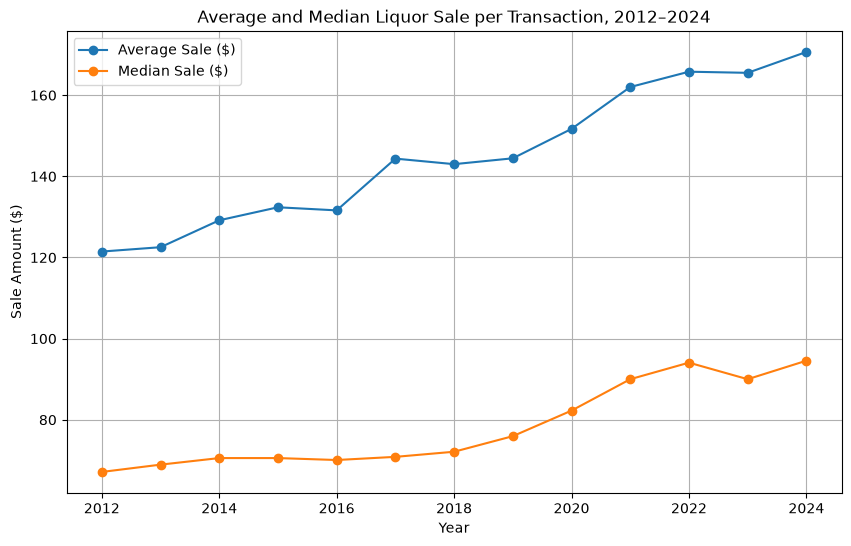

In [11]:
#Looking at the average sales compared to the median sales per transaction by year
import matplotlib.pyplot as plt

iowa_full_years = iowa_sample[(iowa_sample['year'] >= 2012) & (iowa_sample['year'] <= 2024)]

avg_sales_by_year = iowa_full_years.groupby('year')['sale_dollars'].mean()
median_sales_by_year = iowa_full_years.groupby('year')['sale_dollars'].median()

plt.figure(figsize=(10, 6))
plt.plot(avg_sales_by_year.index, avg_sales_by_year.values, marker='o', label='Average Sale ($)')
plt.plot(median_sales_by_year.index, median_sales_by_year.values, marker='o', label='Median Sale ($)')
plt.title('Average and Median Liquor Sale per Transaction, 2012–2024')
plt.xlabel('Year')
plt.ylabel('Sale Amount ($)')
plt.legend()
plt.grid(True)
plt.show()

#The trends of the average and median liquor sale have a sharper increase from 2019 to 2021. It is relatively flat the other years.

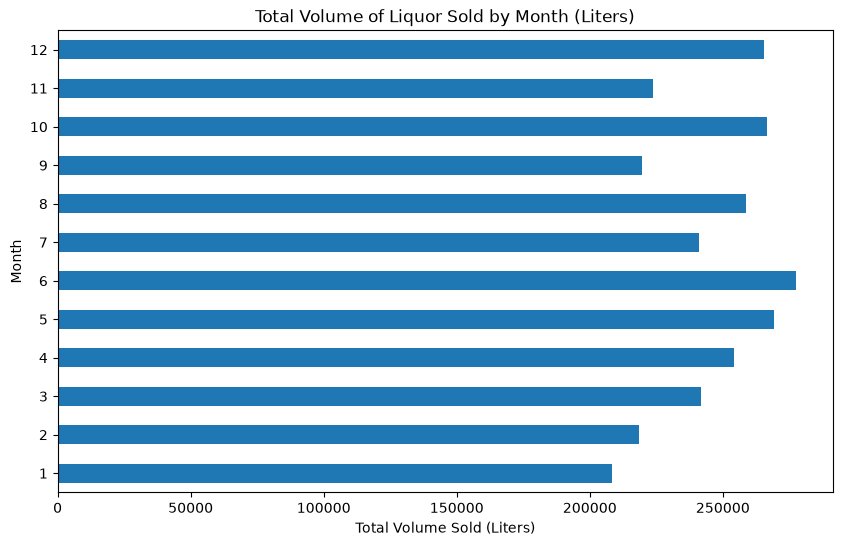

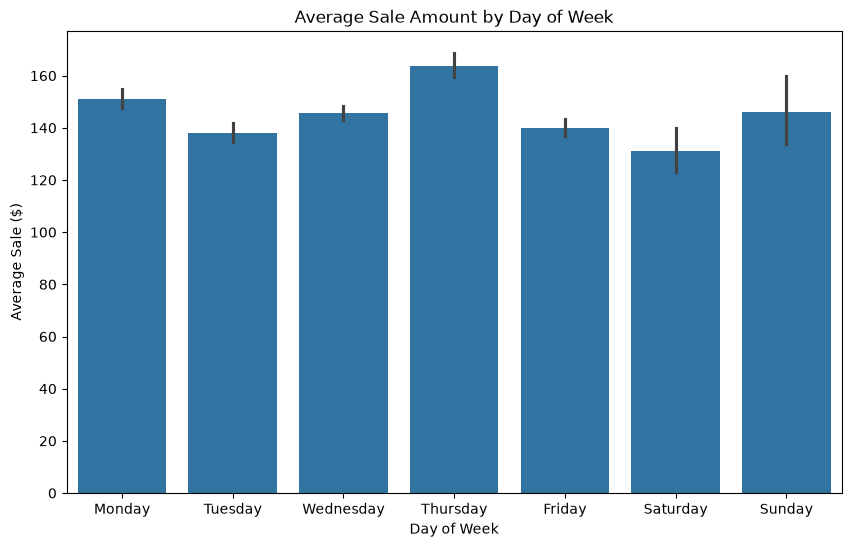

In [13]:
#Looking at the total volume of liquor sold by month in liters
#Looking at the average sale per transaction based on the day of the week
import seaborn as sns
volume_by_month = iowa_sample.groupby('month')['volume_sold_liters'].sum()

plt.figure(figsize=(10, 6))
volume_by_month.plot(kind='barh')
plt.title('Total Volume of Liquor Sold by Month (Liters)')
plt.xlabel('Total Volume Sold (Liters)')
plt.ylabel('Month')
plt.show()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(10, 6))
sns.barplot(x='day_of_week', y='sale_dollars', data=iowa_sample, order=day_order)
plt.title('Average Sale Amount by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Sale ($)')
plt.show()

#December, October, June, and May see the highest sales based on the horizontal bar chart.
#Thursday has the highest average sale amount per transaction when looked at by day of the week in the vertical bar chart.

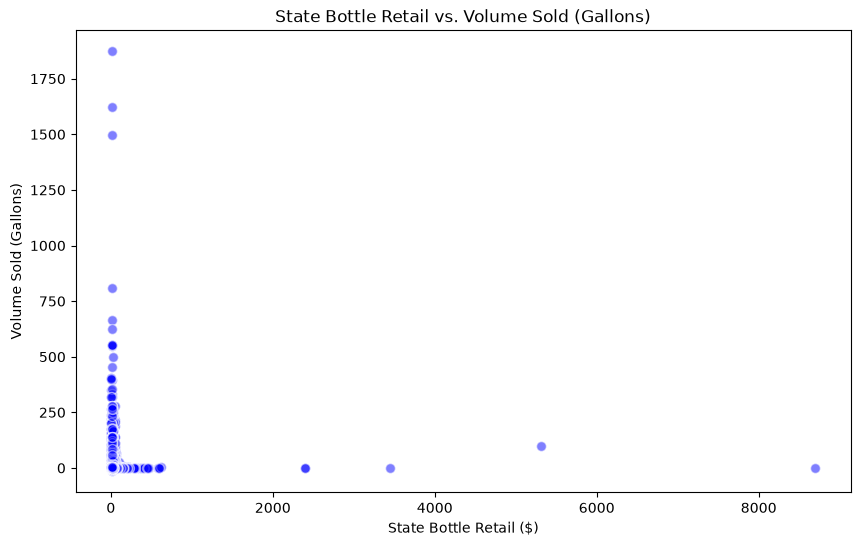

0.00256071037533401


In [14]:
#Correlation between the bottle retail and the volume sold

plt.figure(figsize=(10, 6))
plt.scatter(iowa_sample['state_bottle_retail'], iowa_sample['volume_sold_gallons'], c='blue', alpha=0.5, edgecolors='w', s=50)
plt.title('State Bottle Retail vs. Volume Sold (Gallons)')
plt.xlabel('State Bottle Retail ($)')
plt.ylabel('Volume Sold (Gallons)')
plt.show()
correlation = iowa_sample['state_bottle_retail'].corr(iowa_sample['volume_sold_gallons'])
print(correlation)
#The price of a bottle tells us essentially nothing about how much volume gets sold in that transaction since the correlation is close to 0.
#There is no linear relationship between the two variables.

bottle_volume_ml       97336
pack                   38035
state_bottle_retail    20231
state_bottle_cost      20228
sale_dollars           19437
bottles_sold           15664
volume_sold_gallons    14565
volume_sold_liters     11567
dtype: int64
['bottle_volume_ml', 'pack']


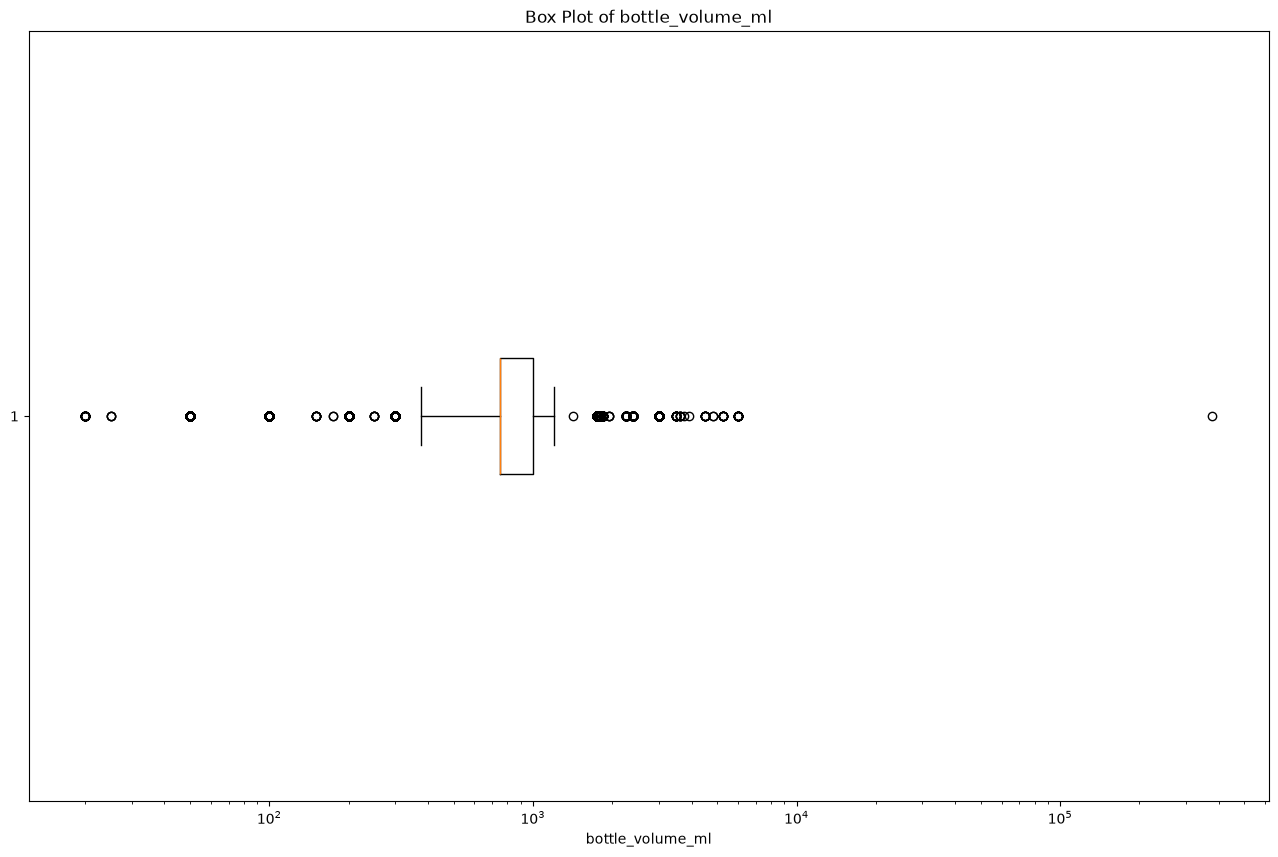

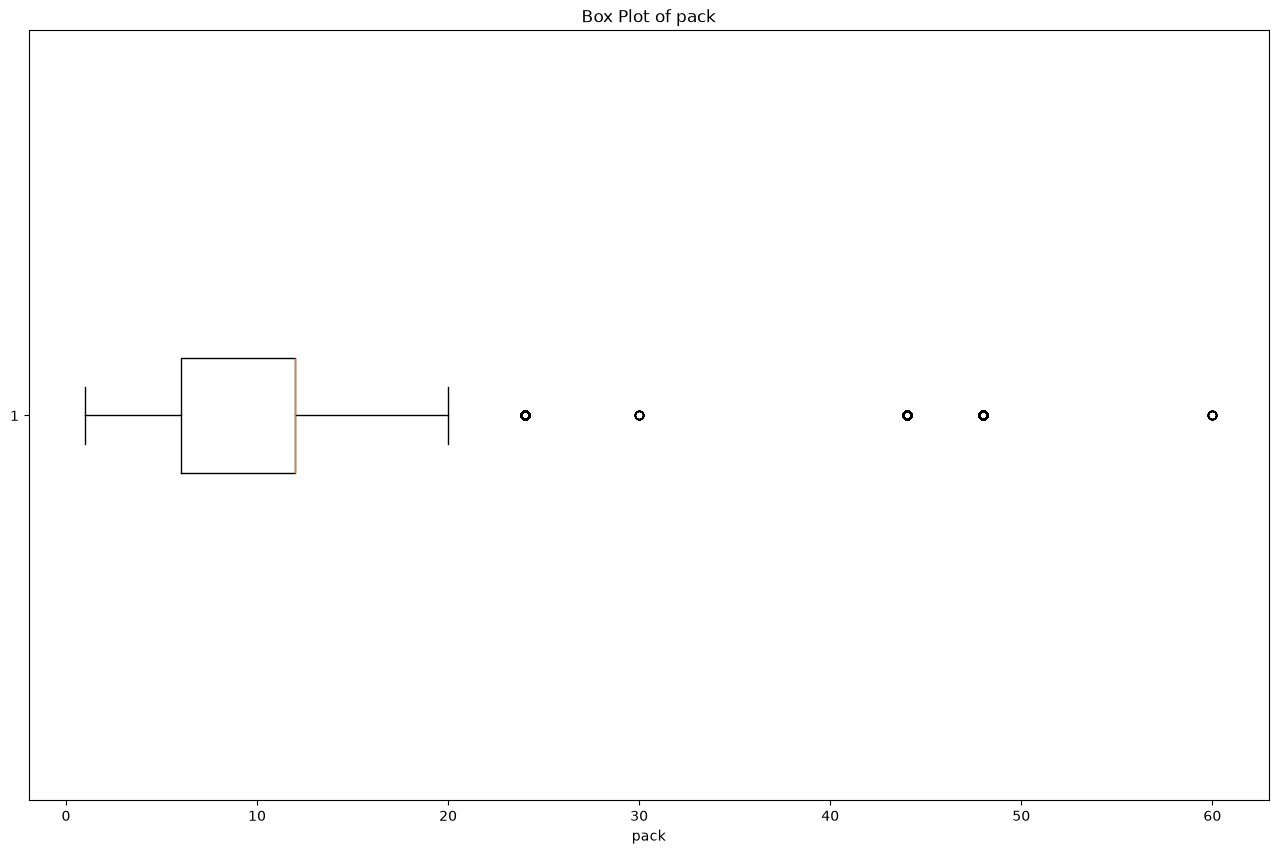

In [18]:
#Looking at the number of outliers with the IQR method and the box plots for the ones with the most outliers
numeric = ['pack', 'bottle_volume_ml', 'state_bottle_cost', 'state_bottle_retail',
           'bottles_sold', 'sale_dollars', 'volume_sold_liters', 'volume_sold_gallons']

Q1 = iowa_sample[numeric].quantile(0.25)
Q3 = iowa_sample[numeric].quantile(0.75)
IQR = Q3 - Q1
outliers = ((iowa_sample[numeric] < (Q1 - 1.5 * IQR)) | (iowa_sample[numeric] > (Q3 + 1.5 * IQR))).sum()

outliers_sorted = outliers.sort_values(ascending=False)
print(outliers_sorted)

top_two = outliers_sorted.head(2).index.tolist()
print(top_two)

plt.figure(figsize=(16, 10))
plt.boxplot(iowa_sample['bottle_volume_ml'], vert=False)
plt.title('Box Plot of bottle_volume_ml')
plt.xlabel('bottle_volume_ml')
plt.xscale('log')
plt.show()

plt.figure(figsize=(16, 10))
plt.boxplot(iowa_sample[top_two[1]], vert=False)
plt.title(f'Box Plot of {top_two[1]}')
plt.xlabel(top_two[1])
plt.show()
#The outliers in the box plot of bottle volume represent actual diversity in the product catalog and that they aren't errors.
#The single 378,000 ml bottle isn't terribly significant, it just shows a bulk order being recorded something that's normally recorded for a single bottle.
#The pack outliers show legitimate bulk order sizes and reflect purchases in bigger quantities.

In [17]:
iowa_sample[iowa_sample['bottle_volume_ml'] > 10000][['item_description', 'bottle_volume_ml', 'pack', 'bottles_sold']]

,item_description,bottle_volume_ml,pack,bottles_sold
130761,18 CASES SMIRNOFF 1.75L/18 CASES CAPTAIN 1.75L,378000,1,1


## Predictive Modeling

### Regression: What drives bottle price?
**Target:** `state_bottle_retail`
**Features:** category, bottle volume, pack size, season, year, plus two engineered flags: `large_format` (≥1,750 ml) and `bulk_pack` (≥12 per pack), which capture pricing shifts at common thresholds.

I excluded `state_bottle_cost`, `sale_dollars`, and `bottles_sold` to avoid data leakage, since retail price is largely a markup of cost. Categorical variables were dummy-coded with `drop_first=True` to avoid multicollinearity.

Using OLS for its interpretable coefficients and p-values, I removed insignificant features. The first model explained only 14% of the variance, and test performance was unexpectedly better than training, which pointed to extreme outliers in the training set. After removing five records priced above \$1,000, the model explained **about 40% of variance (R²)** with a typical error of **about \$11 (RMSE)**. The remaining variation likely comes from factors not in the data, such as brand and age.

### Classification: Predicting product category
I trained a Decision Tree to classify records into the five most common categories using bottle volume, pack size, price, cost, year, season, and the engineered flags. Category and item names were excluded to prevent leakage.

- **Training accuracy:** 86% | **Testing accuracy:** 84%. The small gap suggests the model generalizes well.
- American Vodkas and Canadian Whiskies were predicted most accurately (~90% recall).
- Whiskey Liqueur was weakest (~72% recall), most often confused with Spiced Rum, and Straight Bourbon was often confused with Canadian Whisky. These errors fall between genuinely similar products, which supports price, size, and packaging as meaningful features.

### Next steps
- Try Random Forest models for both tasks to capture non-linear relationships
- Tune hyperparameters and use cross-validation instead of a single split
- Add features such as vendor-level average price or category × volume interactions
- Handle extreme values with robust regression instead of manual exclusion

In [2]:
#Creating the model dataset with state_bottle_retail as the target variable
#Selected features and feature engineering are implemented
#Dummy columns created

iowa_sample['large_format'] = (iowa_sample['bottle_volume_ml'] >= 1750).astype(int)
iowa_sample['bulk_pack'] = (iowa_sample['pack'] >= 12).astype(int)

target = 'state_bottle_retail'
features = ['category_name', 'bottle_volume_ml', 'pack', 'season', 'day_of_week',
            'is_holiday', 'year', 'large_format', 'bulk_pack']

model_data = iowa_sample[features + [target]].copy()
model_data = pd.get_dummies(model_data, columns=['category_name', 'season', 'day_of_week'], drop_first=True)

model_data.head()

#Chose state_bottle_retail as the target because I want to see what is driving the price
#I excluded columns such as state_bottle_cost, sale_dollars, bottles_sold since they are tied to the price of the model so the model is using independent predictors.
#category_name, bottle_volume_ml, and pack should be strong predictors since they are causal relationships tied to pricing.
#Feature engineering with large_format and bulk_pack are meant to capture the idea that pricing will shift at certain thresholds.
#category_name, season, and day_of_week are dummy coded because they are categorical variables without numerical order so the model would not have been able to use them.

,bottle_volume_ml,pack,is_holiday,year,large_format,bulk_pack,state_bottle_retail,category_name_100% AGAVE TEQUILA,category_name_AGED DARK RUM,category_name_AMERICAN ALCOHOL,...,category_name_WHITE RUM,season_Spring,season_Summer,season_Winter,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
0,1750,6,False,2014,1,0,11.76,False,False,False,...,False,True,False,False,True,False,False,False,False,False
1,750,12,False,2014,0,1,10.91,False,False,False,...,False,True,False,False,True,False,False,False,False,False
2,750,12,False,2014,0,1,14.00,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,1000,12,False,2021,0,1,18.89,False,False,False,...,False,False,False,True,False,False,False,True,False,False
4,1750,6,False,2022,1,0,22.50,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [3]:
#Using OLS for the model
#Training on 75% of the data and testing on 25%
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score
from math import sqrt

y = model_data['state_bottle_retail']
X = model_data.drop('state_bottle_retail', axis=1)

X = X.astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=54)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model = sm.OLS(y_train, X_train).fit()
model.summary()
#I will need to make sure I drop one of the categorical columns for each variable that was created into dummy variables to prevent multicollinearity

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     state_bottle_retail   R-squared:                       0.140
Model:                             OLS   Adj. R-squared:                  0.139
Method:                  Least Squares   F-statistic:                     368.6
Date:                 Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                         10:36:23   Log-Likelihood:            -1.1058e+06
No. Observations:               242964   AIC:                         2.212e+06
Df Residuals:                   242856   BIC:                         2.213e+06
Df Model:                          107                                         
Covariance Type:             nonrobust                                         
======================================================================================================================
                                                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
const                                               -784.9281     30.899    -25.403      0.000    -845.489    -724.367
bottle_volume_ml                                       0.0080      0.000     35.730      0.000       0.008       0.008
pack                                                  -0.3056      0.008    -36.111      0.000      -0.322      -0.289
is_holiday                                             0.1008      0.353      0.286      0.775      -0.591       0.792
year                                                   0.3978      0.015     25.975      0.000       0.368       0.428
large_format                                         -14.9230      0.328    -45.465      0.000     -15.566     -14.280
bulk_pack                                            -12.1448      0.176    -68.887      0.000     -12.490     -11.799
category_name_100% AGAVE TEQUILA                      17.1945      0.897     19.174      0.000      15.437      18.952
category_name_AGED DARK RUM                            5.5357      1.316      4.206      0.000       2.956       8.115
category_name_AMERICAN ALCOHOL                         6.5615      1.859      3.529      0.000       2.917      10.206
category_name_AMERICAN AMARETTO                       -0.9120      1.463     -0.623      0.533      -3.780       1.956
category_name_AMERICAN BRANDIES                        1.2441      0.910      1.367      0.172      -0.540       3.028
category_name_AMERICAN COCKTAILS                      -1.3073      0.974     -1.342      0.180      -3.217       0.602
category_name_AMERICAN CORDIALS & LIQUEURS             4.5258      0.920      4.918      0.000       2.722       6.329
category_name_AMERICAN DISTILLED SPIRITS SPECIALTY     3.8841      1.379      2.816      0.005       1.181       6.587
category_name_AMERICAN DRY GINS                        0.9440      0.904      1.044      0.297      -0.829       2.717
category_name_AMERICAN FLAVORED VODKA                  2.1166      0.883      2.397      0.017       0.386       3.847
category_name_AMERICAN GRAPE BRANDIES                  3.7797      1.003      3.769      0.000       1.814       5.745
category_name_AMERICAN SCHNAPPS                        5.3798      0.900      5.979      0.000       3.616       7.143
category_name_AMERICAN SLOE GINS                      -1.1814      2.585     -0.457      0.648      -6.249       3.886
category_name_AMERICAN VODKAS                          0.6997      0.857      0.817      0.414      -0.979       2.378
category_name_ANISETTE                                 1.0634      6.964      0.153      0.879     -12.586      14.713
category_name_APPLE SCHNAPPS                           3.6763      1.633      2.251      0.024   

In [4]:
#Trimmed the features that weren't of significance
#Used drop_first=True to prevent multicollinearity
features_trimmed = ['category_name', 'bottle_volume_ml', 'pack', 'season', 'year', 'large_format', 'bulk_pack']

model_data2 = iowa_sample[features_trimmed + [target]].copy()
model_data2 = pd.get_dummies(model_data2, columns=['category_name', 'season'], drop_first=True)

y2 = model_data2[target]
X2 = model_data2.drop(target, axis=1).astype(int)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=54)
X2_train = sm.add_constant(X2_train)
X2_test = sm.add_constant(X2_test)

model2 = sm.OLS(y2_train, X2_train).fit()
model2.summary()
#This is the model with the R-Squared value of 0.14. Insignificant variables were removed. 
#Some insignificant variables still exist because the other dummy variables of the same category have significance.

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     state_bottle_retail   R-squared:                       0.140
Model:                             OLS   Adj. R-squared:                  0.139
Method:                  Least Squares   F-statistic:                     394.3
Date:                 Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                         10:36:28   Log-Likelihood:            -1.1058e+06
No. Observations:               242964   AIC:                         2.212e+06
Df Residuals:                   242863   BIC:                         2.213e+06
Df Model:                          100                                         
Covariance Type:             nonrobust                                         
======================================================================================================================
                                                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
const                                               -780.4745     30.364    -25.704      0.000    -839.987    -720.962
bottle_volume_ml                                       0.0080      0.000     35.757      0.000       0.008       0.008
pack                                                  -0.3055      0.008    -36.106      0.000      -0.322      -0.289
year                                                   0.3957      0.015     26.277      0.000       0.366       0.425
large_format                                         -14.9287      0.328    -45.504      0.000     -15.572     -14.286
bulk_pack                                            -12.1477      0.176    -68.916      0.000     -12.493     -11.802
category_name_100% AGAVE TEQUILA                      17.1851      0.897     19.164      0.000      15.427      18.943
category_name_AGED DARK RUM                            5.5205      1.316      4.195      0.000       2.941       8.100
category_name_AMERICAN ALCOHOL                         6.5661      1.859      3.531      0.000       2.922      10.210
category_name_AMERICAN AMARETTO                       -0.9148      1.463     -0.625      0.532      -3.783       1.953
category_name_AMERICAN BRANDIES                        1.2288      0.910      1.350      0.177      -0.555       3.013
category_name_AMERICAN COCKTAILS                      -1.3118      0.974     -1.346      0.178      -3.221       0.598
category_name_AMERICAN CORDIALS & LIQUEURS             4.5038      0.920      4.895      0.000       2.700       6.307
category_name_AMERICAN DISTILLED SPIRITS SPECIALTY     3.8643      1.379      2.802      0.005       1.161       6.567
category_name_AMERICAN DRY GINS                        0.9314      0.904      1.030      0.303      -0.841       2.704
category_name_AMERICAN FLAVORED VODKA                  2.1012      0.883      2.380      0.017       0.371       3.832
category_name_AMERICAN GRAPE BRANDIES                  3.7800      1.003      3.769      0.000       1.814       5.746
category_name_AMERICAN SCHNAPPS                        5.3604      0.900      5.958      0.000       3.597       7.124
category_name_AMERICAN SLOE GINS                      -1.1957      2.585     -0.462      0.644      -6.263       3.872
category_name_AMERICAN VODKAS                          0.6783      0.856      0.792      0.428      -1.000       2.357
category_name_ANISETTE                                 1.0762      6.964      0.155      0.877     -12.573      14.726
category_name_APPLE SCHNAPPS                           3.6560      1.633      2.239      0.025       0.456       6.856
category_name_APRICOT BRANDIES                         2.5041      1.581      1.584      0.113   

In [5]:
#New model trained and tested with the selected variables
y2_train_pred = model2.predict(X2_train)
y2_test_pred = model2.predict(X2_test)
train_r2 = r2_score(y2_train, y2_train_pred)
test_r2 = r2_score(y2_test, y2_test_pred)
train_rmse = sqrt(mean_squared_error(y2_train, y2_train_pred))
test_rmse = sqrt(mean_squared_error(y2_test, y2_test_pred))

print(f"Training R-squared: {train_r2:.4f}")
print(f"Testing R-squared: {test_r2:.4f}")
print(f"Training RMSE: {train_rmse:.4f}")
print(f"Testing RMSE: {test_rmse:.4f}")
#This is not what I would expect for training and testing. It would make sense to check if there is an outlier in the training data.

Training R-squared: 0.1397
Testing R-squared: 0.6638
Training RMSE: 22.9237
Testing RMSE: 13.5792


In [6]:
iowa_sample['state_bottle_retail'].describe()
iowa_sample['state_bottle_retail'].sort_values(ascending=False).head(10)

70231     8700.00
130761    5305.95
221562    3448.26
306322    2398.79
251885    2398.79
71246      623.40
67551      600.15
214504     600.00
60264      585.00
66610      585.00
Name: state_bottle_retail, dtype: float64

In [7]:
iowa_sample[iowa_sample['state_bottle_retail'] > 1000][['item_description', 'category_name', 'bottle_volume_ml', 'pack', 'state_bottle_retail']]

,item_description,category_name,bottle_volume_ml,pack,state_bottle_retail
70231,CEDAR RIDGE BARREL PROOF BOURBON - USE CODE 92...,AMERICAN VODKAS,750,1,8700.00
130761,18 CASES SMIRNOFF 1.75L/18 CASES CAPTAIN 1.75L,AMERICAN VODKAS,378000,1,5305.95
221562,REMY MARTIN LOUIS XIII,IMPORTED BRANDIES,750,1,3448.26
251885,REMY MARTIN LOUIS XIII COGNAC,SPECIAL ORDER ITEMS,750,1,2398.79
306322,REMY MARTIN LOUIS XIII COGNAC,SPECIAL ORDER ITEMS,750,1,2398.79


In [8]:
#Creates a new model where the bottle retail is less than 1000 and uses the selected features from before.
model_data3 = iowa_sample[iowa_sample['state_bottle_retail'] <= 1000][features_trimmed + [target]].copy()
model_data3 = pd.get_dummies(model_data3, columns=['category_name', 'season'], drop_first=True)
y3 = model_data3[target]
X3 = model_data3.drop(target, axis=1).astype(int)
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.25, random_state=54)
X3_train = sm.add_constant(X3_train)
X3_test = sm.add_constant(X3_test)
model3 = sm.OLS(y3_train, X3_train).fit()
y3_train_pred = model3.predict(X3_train)
y3_test_pred = model3.predict(X3_test)

print(f"Training R-squared: {r2_score(y3_train, y3_train_pred):.4f}")
print(f"Testing R-squared: {r2_score(y3_test, y3_test_pred):.4f}")
print(f"Training RMSE: {sqrt(mean_squared_error(y3_train, y3_train_pred)):.4f}")
print(f"Testing RMSE: {sqrt(mean_squared_error(y3_test, y3_test_pred)):.4f}")
#After removing outliers and insignificant features, about 40% of the variation in bottle retail price can be explained with the data.
#The remaining 60% is likely factors that are not included within this dataset.
#Typically predictions are off by about $11 for the bottle retail amount.

Training R-squared: 0.4024
Testing R-squared: 0.4182
Training RMSE: 11.1247
Testing RMSE: 10.7222


In [9]:
#Filters the data to the top 5 categories and builds a Decision Tree classifier
#Uses bottle volume, pack, price, year, season, and the engineered flags as features (excludes category_name and item_description to avoid leakage)
#Reports training and testing accuracy using a 75/25 split

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

top5_categories = iowa_sample['category_name'].value_counts().head(5).index.tolist()
print(top5_categories)

iowa_top5 = iowa_sample[iowa_sample['category_name'].isin(top5_categories)].copy()

class_features = ['bottle_volume_ml', 'pack', 'state_bottle_retail', 'state_bottle_cost',
                   'year', 'season', 'large_format', 'bulk_pack']

class_data = iowa_top5[class_features + ['category_name']].copy()
class_data = pd.get_dummies(class_data, columns=['season'], drop_first=True)

y_class = class_data['category_name']
X_class = class_data.drop('category_name', axis=1)
X_class = X_class.astype(int)

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class, y_class, test_size=0.25, random_state=54
)

tree_model = DecisionTreeClassifier(random_state=54)
tree_model.fit(X_class_train, y_class_train)
y_class_train_pred = tree_model.predict(X_class_train)
y_class_test_pred = tree_model.predict(X_class_test)

train_accuracy = accuracy_score(y_class_train, y_class_train_pred)
test_accuracy = accuracy_score(y_class_test, y_class_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")
#Training accuracy (0.86) and testing accuracy (0.84) are close together, meaning the model generalizes well and isn't overfitting.

['AMERICAN VODKAS', 'CANADIAN WHISKIES', 'STRAIGHT BOURBON WHISKIES', 'WHISKEY LIQUEUR', 'SPICED RUM']
Training Accuracy: 0.8618
Testing Accuracy: 0.8434


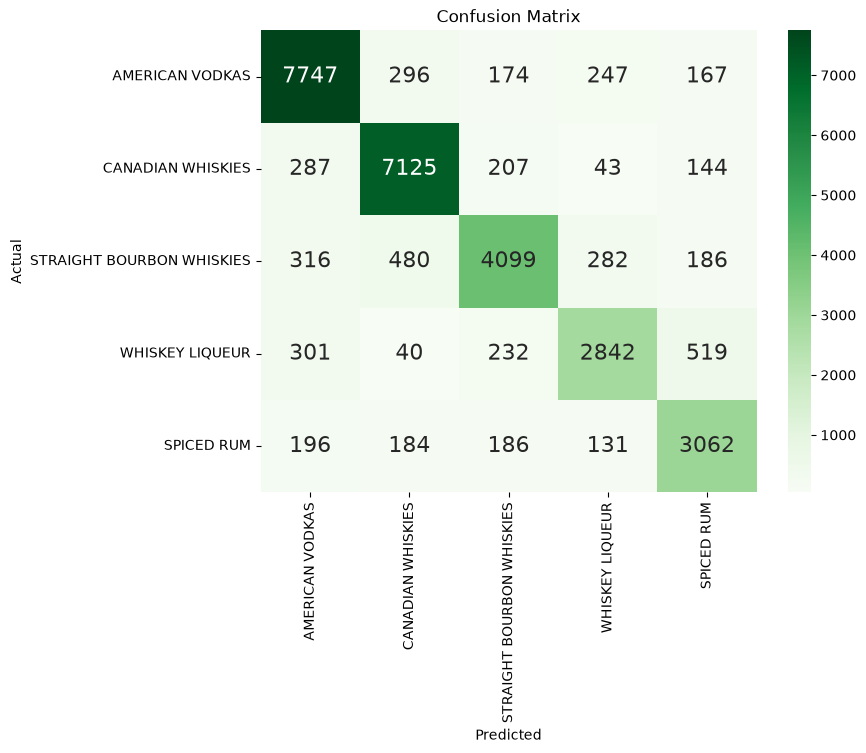

In [10]:
#Builds a confusion matrix and heatmap to see which categories the model confuses most often
import matplotlib.pyplot as plt
import seaborn as sns
conf_matrix = confusion_matrix(y_class_test, y_class_test_pred, labels=top5_categories)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Greens', annot_kws={"size": 16},
            xticklabels=top5_categories, yticklabels=top5_categories)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
#American Vodkas and Canadian Whiskies were predicted most accurately (~90% recall each).
#Whiskey Liqueur was the weakest category (~72% recall), most often confused with Spiced Rum, likely because both are flavored, similarly priced/packaged spirits.
#Straight Bourbon Whiskies was also frequently confused with Canadian Whiskies, likely since both are standard aged whiskeys with similar profiles.
#This suggests the model is confusing genuinely similar products rather than making random errors, which supports that bottle size/price/pack are meaningful features for this task.

## Product Segmentation (K-Means)

I clustered records on category, bottle volume, pack size, season, year, price, cost, and the engineered flags, scaling features with `StandardScaler` so large-valued columns didn't dominate the distance calculation.

The initial elbow method and silhouette analysis pointed to two highly unbalanced clusters, which were driven by extreme outliers. After excluding records priced above \$1,000 and rerunning the elbow method, **five clusters** emerged as the best fit. The fitted model was then applied to the full sample.

### Key findings
- **Clear price tiers:** Average retail price ranges from \$7.39 (cluster 2) to \$40.26 (cluster 0), about a 5× spread.
- **Distinct product groups:** Each cluster has a different dominant category: Special Order Items, American Vodkas, Peppermint Schnapps, and Tequila. The clusters reflect real product differences, not just price.
- **Size vs. pack tradeoff:** One cluster combines large bottles (~1,436 ml) with small packs (5.8), while another pairs small bottles (~641 ml) with large packs (14.6).
- **Uniform margins:** Profit margin is nearly identical across clusters (33.3–33.5%) despite the price spread, consistent with a standard state markup regardless of product type.
- **Order size:** Cluster 0 has the highest average sale (\$295) and bottles per order (17), likely reflecting special orders, while cluster 2 has the lowest (\$48, 6.9 bottles).
- **Standard bottle sizes:** The scatter plot shows bottle sizes concentrate in industry-standard bands (50, 375, 750, 1,750 ml, etc.). Around 750 ml, clusters are separated mainly by price tier, while 1,750 ml handles form their own group.

### Next steps
A density-based method such as DBSCAN could capture irregularly shaped clusters that K-Means misses.

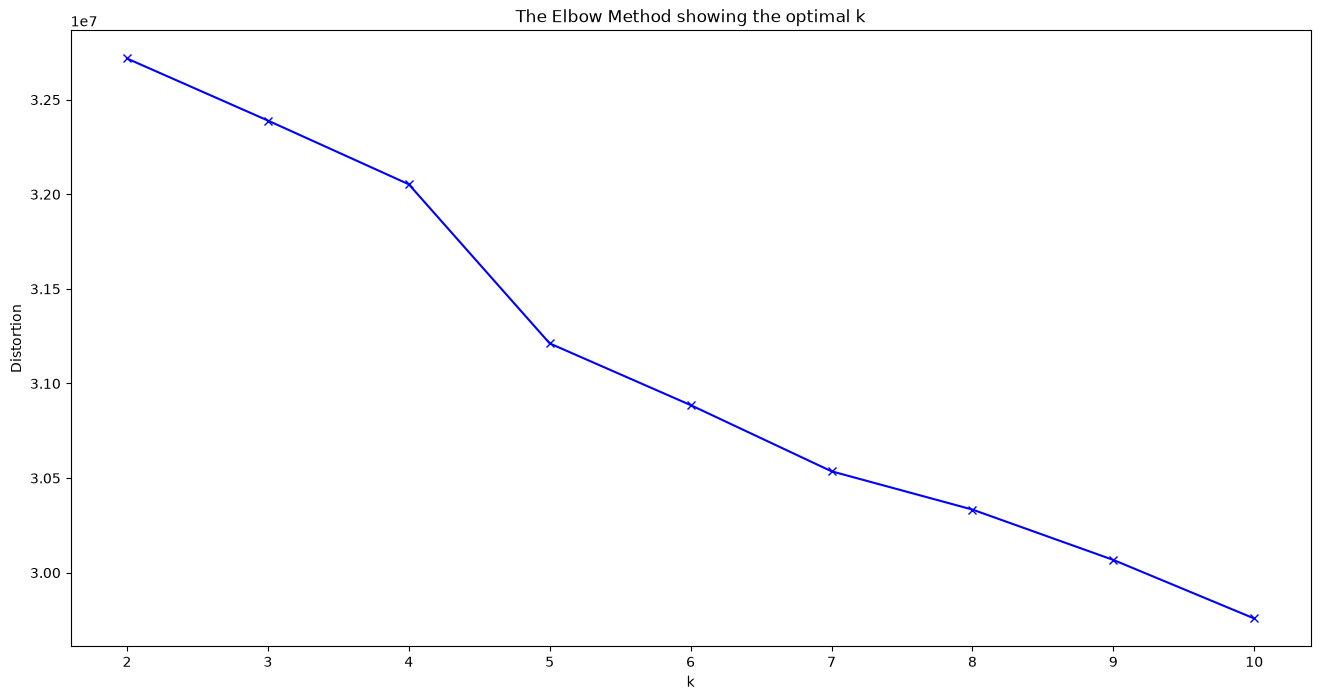

In [20]:
iowa_filtered = iowa_sample[iowa_sample['state_bottle_retail'] <= 1000].copy()

cluster_features = ['category_name', 'bottle_volume_ml', 'pack', 'season', 'year',
                     'large_format', 'bulk_pack', 'state_bottle_retail', 'state_bottle_cost']

cluster_data = iowa_filtered[cluster_features].copy()
cluster_data = pd.get_dummies(cluster_data, columns=['category_name', 'season'], drop_first=True)
cluster_data = cluster_data.astype(int)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)
from sklearn.cluster import KMeans
distortions = []
K = range(2, 11)
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=54)
    kmeanModel.fit(cluster_scaled)
    distortions.append(kmeanModel.inertia_)

plt.figure(figsize=(16, 8))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')
plt.show()

In [21]:
kmeans_final = KMeans(n_clusters=5, random_state=54)
kmeans_final.fit(cluster_scaled)

full_cluster_data = iowa_sample[cluster_features].copy()
full_cluster_data = pd.get_dummies(full_cluster_data, columns=['category_name', 'season'], drop_first=True)
full_cluster_data = full_cluster_data.astype(int)

full_cluster_scaled = scaler.transform(full_cluster_data)

iowa_sample['Clusters'] = kmeans_final.predict(full_cluster_scaled)

iowa_sample['Clusters'].value_counts()

Clusters
4    226691
1     91285
3      4425
2      1210
0       341
Name: count, dtype: int64

In [23]:
top_category_by_cluster = iowa_sample.groupby('Clusters')['category_name'].agg(lambda x: x.value_counts().index[0])
print(top_category_by_cluster)

season_by_cluster = pd.crosstab(iowa_sample['Clusters'], iowa_sample['season'], normalize='index') * 100
print(season_by_cluster.round(1))

profit_by_cluster = iowa_sample.groupby('Clusters')['profit_margin_pct'].mean()
print(profit_by_cluster)

sales_by_cluster = iowa_sample.groupby('Clusters')[['bottles_sold', 'sale_dollars']].mean()
print(sales_by_cluster)

Clusters
0    SPECIAL ORDER ITEMS
1        AMERICAN VODKAS
2    PEPPERMINT SCHNAPPS
3                TEQUILA
4        AMERICAN VODKAS
Name: category_name, dtype: str
season    Fall  Spring  Summer  Winter
Clusters                              
0         27.3    22.0    24.6    26.1
1         24.4    26.7    25.9    22.9
2         20.0    27.4    25.5    27.2
3         19.2    29.2    27.5    24.0
4         24.3    26.5    25.6    23.6
Clusters
0    33.339380
1    33.372634
2    33.354571
3    33.482148
4    33.380718
Name: profit_margin_pct, dtype: float64
          bottles_sold  sale_dollars
Clusters                            
0            17.076246    295.360968
1             8.710434    186.789474
2             6.912397     48.014893
3             9.301017    154.919765
4            11.854255    131.658321


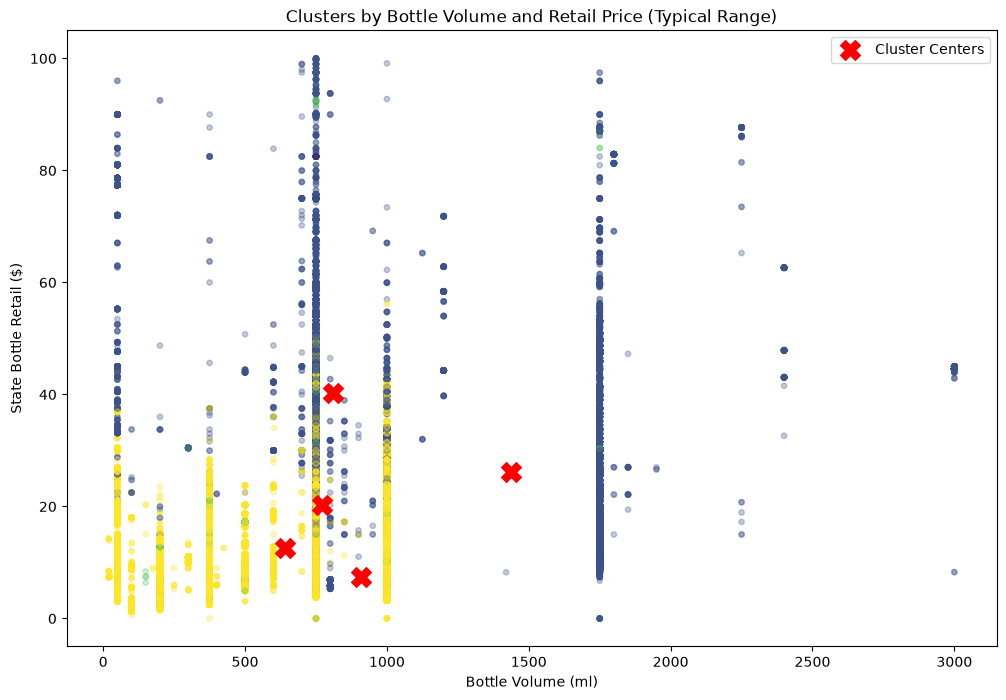

In [26]:
plot_data = iowa_sample[(iowa_sample['bottle_volume_ml'] <= 3000) & (iowa_sample['state_bottle_retail'] <= 100)]

plt.figure(figsize=(12, 8))
plt.scatter(plot_data['bottle_volume_ml'], plot_data['state_bottle_retail'],
            c=plot_data['Clusters'], cmap='viridis', alpha=0.3, s=15)

cluster_centers = iowa_sample.groupby('Clusters')[['bottle_volume_ml', 'state_bottle_retail']].mean()
plt.scatter(cluster_centers['bottle_volume_ml'], cluster_centers['state_bottle_retail'],
            c='red', s=200, marker='X', label='Cluster Centers')

plt.title('Clusters by Bottle Volume and Retail Price (Typical Range)')
plt.xlabel('Bottle Volume (ml)')
plt.ylabel('State Bottle Retail ($)')
plt.legend()
plt.show()

### What the cluster scatter plot shows

- **Insight 1:** Bottle sizes cluster into distinct vertical bands rather than a continuum (around 50, 200, 375, 500, 750, 1000, 1200, 1750, and 3000ml), confirming liquor bottles come in standardized industry sizes rather than varying freely.

- **Insight 2:** The largest cluster (4, shown in yellow) dominates the lower-price range across nearly every bottle size rather than being tied to one specific volume, meaning it probably represents a broad "everyday/mainstream purchase" segment defined more by price than size.

- **Insight 3:** The 1750ml (handle-size) column is visually dominated by a different, darker cluster, consistent with cluster 1's characteristics (largest average volume, dominant category American Vodkas), suggesting handle-sized bottles form their own distinct group.

- **Insight 4:** Several cluster centers overlap around the 750-900ml range at different price heights (~\$7, \$13, \$20, \$40), showing that in this common size range, clusters are distinguished primarily by price tier rather than by volume.

- **Insight 5:** Data becomes sparser and more scattered above 2000ml, showing that large-format bottles beyond standard sizes make up a smaller, more heterogeneous slice of the market.

## Key Takeaways

- Sales follow clear seasonal patterns, peaking in December, with smaller peaks in June and October.
- Transaction size rose sharply from 2019–2021, consistent with larger, less frequent orders during COVID-19.
- Product attributes (category, size, pack) explain a meaningful share of price but not most of it. Brand and age likely account for much of the rest.
- Price, size, and packaging are strong enough signals to classify product category with 84% accuracy.
- Margins are nearly uniform (~33%) across every price tier, pointing to a standardized pricing structure.